# Third particle set: Poincare returns from the thesis reference campaign

This notebook reads the campaign and representative radius from the thesis registry `TFM_redaccion/datos/campana_referencia.json`. The current reference is `main-20261117-rho-div20`, with representative `rho = 0.015`. It extracts IDs 12, 15, 18, 21, 24, 27, 30 and 33 from its verified `BM4Implicit` archive without launching an integration. The radius reaches gyroaveraging unchanged in base-cell widths; the physical radius is provenance only.

The source has 84 independent particles, 5000 forcing cycles, 40 fixed steps and ten saved samples per cycle. Only whole-cycle returns are selected. Exact positions, IDs and original colors remain unchanged. Earlier campaign directories and their products retain their original parameters.


In [1]:
export_thesis_figure = True
first_cycle = 1
last_cycle = None  # None selects all complete cycles recorded by the reference campaign.
show_legend = False
view_limits = (0.0, 1.0)


In [2]:
from pathlib import Path
from shutil import copyfile
from hashlib import file_digest, sha256
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
import numpy as np

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/potential/potential.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Run this notebook inside GC2D_codigo.")
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))
from studies.main_campaign import SOURCE_SHA256, campaign_case_key, campaign_rho_label

reference_path = root.parent / "TFM_redaccion/datos/campana_referencia.json"
reference = json.loads(reference_path.read_text())
if reference["schema_version"] != 1 or reference["rho_convention"] != "base_cell_width":
    raise ValueError("Unsupported thesis reference registry.")
campaign_dir = root / reference["campaign_path"]
if campaign_dir.name != reference["campaign_id"]:
    raise ValueError("The reference campaign directory and identifier disagree.")
campaign = json.loads((campaign_dir / "campaign.json").read_text())
for key in ("config", "methods", "source_sha256", "code_sha256", "bucket"):
    if campaign[key] != reference[key]:
        raise ValueError(f"Reference campaign mismatch: {key}")
if campaign["rhos"] != reference["rho_values"]:
    raise ValueError("The reference rho grid differs from the saved campaign.")
rho = reference["representative_rho"]
if rho not in campaign["rhos"]:
    raise ValueError("The representative rho is absent from the reference campaign.")
case_key = campaign_case_key(rho, "BM4Implicit")
case_dir = campaign_dir / "runs" / case_key
progress = json.loads((campaign_dir / "progress.json").read_text())
if progress["cases"][case_key]["status"] != "complete":
    raise ValueError("The selected reference case is not verified and complete.")
reference_provenance = {
    "reference_registry": "TFM_redaccion/datos/campana_referencia.json",
    "reference_registry_sha256": sha256(reference_path.read_bytes()).hexdigest(),
    "campaign_id": reference["campaign_id"],
    "campaign_sha256": sha256((campaign_dir / "campaign.json").read_bytes()).hexdigest(),
    "website_url": reference["website_url"], "bucket": reference["bucket"],
}
cycles = campaign["config"]["cycles"]
steps_per_cycle = campaign["config"]["steps_per_cycle"]
samples_per_cycle = campaign["config"]["samples_per_cycle"]
if last_cycle is None:
    last_cycle = cycles
if not (case_dir / "manifest.json").is_file():
    raise FileNotFoundError(f"The selected reference case is unavailable: {case_dir}")
manifest = json.loads((case_dir / "manifest.json").read_text())
for name in ("metadata.json", "solution.npz"):
    path = case_dir / name
    expected = manifest["files"][name]
    if path.stat().st_size != expected["bytes"]:
        raise ValueError(f"Archive size mismatch: {name}")
    with path.open("rb") as stream:
        if file_digest(stream, "sha256").hexdigest() != expected["sha256"]:
            raise ValueError(f"Archive checksum mismatch: {name}")

metadata = json.loads((case_dir / "metadata.json").read_text())
experiment = metadata["experiment"]
diagnostics = metadata["diagnostics"]
if metadata["schema_version"] != 3 or metadata["layout"] != "gc_component_major_xy":
    raise ValueError("Expected row-major GC archive schema 3.")
if experiment["schema_version"] != 2 or experiment["rho"] != rho or experiment["rho_runtime"] != rho:
    raise ValueError("Expected the reference schema-2 campaign with direct rho.")
np.testing.assert_allclose(experiment["rho_m"], rho * experiment["spatial_scale_m"], rtol=0, atol=1e-15)
assert experiment["study"] == "main_reflected_campaign" and experiment["method"] == "BM4Implicit"
assert experiment["config"] == dict(cycles=cycles, steps_per_cycle=steps_per_cycle,
                                    samples_per_cycle=samples_per_cycle)
assert experiment["source_sha256"] == SOURCE_SHA256 == reference["source_sha256"]
assert experiment["code_sha256"] == reference["code_sha256"]
assert experiment["spatial_extension"] == "reflected" and experiment["spatial_period"] == 2.0
assert experiment["position_wrapping"] == "none" and experiment["cycle_duration"] == 1.0
assert experiment["magnetic_field"] == 1.5
assert experiment["energy_evaluation"] == "physical_hamiltonian_at_saved_states"
assert {"physical_hamiltonian", "hamiltonian_time_derivative"} <= diagnostics.keys()
assert not {"energy_integral", "energy_balance", "energy_quadrature_difference"} & diagnostics.keys()
assert diagnostics["step_count"]["scalar"] == cycles * steps_per_cycle
assert diagnostics["output_interpolation_count"]["scalar"] == 0
assert diagnostics["execution_backend"]["scalar"] == "jax"

source_file = root / "data/particles/chaotic_candidates.json"
dataset = json.loads(source_file.read_text())
particles = dataset["particles"]
particle_ids = np.array([p["id"] for p in particles], dtype=int)
np.testing.assert_array_equal(particle_ids, [12, 15, 18, 21, 24, 27, 30, 33])
assert dataset["particle_count"] == len(particles) == 8
assert dataset["source_sha256"] == experiment["source_sha256"]
originals = experiment["particle_record"]["particles"]
assert [p["id"] for p in originals] == list(range(1, 85))
indices = {p["id"]: i for i, p in enumerate(originals)}
selection = [indices[int(pid)] for pid in particle_ids]
assert particles == [originals[i] for i in selection]
colors = [p["color"] for p in particles]


## Verify and extract complete-cycle returns

The archive is checked against its SHA-256 manifest, direct-radius metadata, particle records, layout, float64 state shape and completed step count. A missing reference result stops execution; the notebook never falls back to old results. It reads the direct Hamiltonian convention and rejects the historical quadrature diagnostic keys.


In [3]:
with np.load(case_dir / "solution.npz", allow_pickle=False) as source_archive:
    all_times = source_archive["t"]
    all_states = source_archive["states"]
assert all_states.shape == (cycles * samples_per_cycle + 1, 168)
assert all_states.dtype == np.float64 and np.isfinite(all_states).all()
initial_xy = np.asarray(experiment["initial_positions"])
assert initial_xy.shape == (84, 2)
np.testing.assert_array_equal(all_states[0], initial_xy.T.ravel())
np.testing.assert_allclose(initial_xy[selection], [p["cell_fraction"] for p in particles], rtol=0, atol=1e-12)
expected_times = np.arange(cycles * samples_per_cycle + 1) * (steps_per_cycle // samples_per_cycle) / steps_per_cycle
np.testing.assert_allclose(all_times, expected_times, rtol=0, atol=1e-10)
times = all_times[::samples_per_cycle]
np.testing.assert_array_equal(times, np.arange(cycles + 1, dtype=float))
returns = all_states[::samples_per_cycle].reshape(cycles + 1, 2, 84).transpose(0, 2, 1)[:, selection, :]
np.testing.assert_array_equal(returns[0], initial_xy[selection])
states = returns.transpose(0, 2, 1).reshape(cycles + 1, 16)
configuration = {
    **reference_provenance,
    "source_case": str(case_dir.relative_to(root)), "method": "BM4Implicit",
    "rho_study": rho, "rho_runtime": experiment["rho_runtime"], "rho_m": experiment["rho_m"],
    "rho_convention": "base_cell_widths", "spatial_scale_m": experiment["spatial_scale_m"],
    "cycles": cycles, "steps_per_cycle": steps_per_cycle, "samples_per_cycle": samples_per_cycle,
    "particle_ids": particle_ids.tolist(), "particle_colors": colors,
    "dataset": str(source_file.relative_to(root)), "dataset_sha256": sha256(source_file.read_bytes()).hexdigest(),
    "source_code_sha256": experiment["code_sha256"], "potential_sha256": experiment["source_sha256"],
    "source_archive_sha256": manifest["files"]["solution.npz"]["sha256"],
    "source_metadata_sha256": manifest["files"]["metadata.json"]["sha256"],
    "spatial_extension": "reflected", "spatial_period": 2.0, "position_wrapping": "none",
    "energy_evaluation": experiment["energy_evaluation"], "trajectory_integrations": 0,
}
output_dir = campaign_dir / "postprocessing/chapter4/current"
output_dir.mkdir(parents=True, exist_ok=True)
archive_path = output_dir / f"third_set_{case_key}.npz"
np.savez_compressed(archive_path, times=times, states=states,
                    metadata=np.asarray(json.dumps(configuration, sort_keys=True)))
print(f"Verified {cycles * steps_per_cycle} steps for 84 particles; extracted {len(times)} rows for {len(particles)} particles.")
print(f"rho = {rho}; runtime rho = {experiment['rho_runtime']}; physical radius = {experiment['rho_m']:.12g} m.")


Verified 200000 steps for 84 particles; extracted 5001 rows for 8 particles.
rho = 0.015; runtime rho = 0.015; physical radius = 0.0027 m.


## Plot the selected returns

Coordinates remain unwrapped. The unit-square viewport is a display choice; returns outside it are retained and counted. The figure alone does not establish chaos, confinement, convergence or periodicity. Plot labels are in French.


Displayed cycles: 1–5000; returns: 40000.
Outside the viewport (retained in the archive): 3164.


Exported tercer_conjunto_poincare_fr: PNG, PDF and numerical provenance.
Exported tercer_conjunto_poincare_fr: PNG, PDF and numerical provenance.


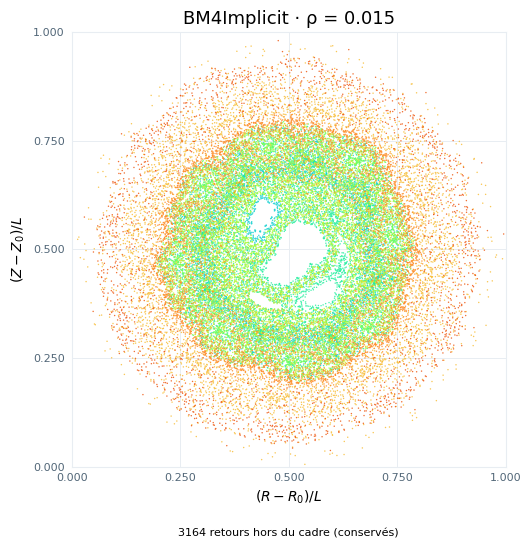

In [4]:
if not isinstance(first_cycle, int) or not 1 <= first_cycle <= cycles:
    raise ValueError("first_cycle must be between 1 and cycles.")
if not isinstance(last_cycle, int) or not first_cycle <= last_cycle <= cycles:
    raise ValueError("last_cycle must be between first_cycle and cycles.")
lo, hi = view_limits
if not np.isfinite([lo, hi]).all() or lo >= hi:
    raise ValueError("view_limits must be increasing finite bounds.")
plotted = returns[first_cycle:last_cycle + 1]
outside = np.any((plotted < lo) | (plotted > hi), axis=2)
print(f"Displayed cycles: {first_cycle}–{last_cycle}; returns: {plotted.shape[0] * len(particles)}.")
print(f"Outside the viewport (retained in the archive): {int(outside.sum())}.")

with plt.rc_context({"font.size": 10, "axes.titlesize": 13,
                     "axes.labelsize": 10, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "pdf.fonttype": 42, "savefig.facecolor": "white"}):
    fig, ax = plt.subplots(figsize=(5.2, 5.5), layout="constrained")
    for index, (particle_id, color) in enumerate(zip(particle_ids, colors)):
        ax.scatter(plotted[:, index, 0], plotted[:, index, 1], s=1.1,
                   color=color, alpha=0.85, edgecolors="none", rasterized=True,
                   label=f"Particule {particle_id}")
    ax.set(title=f"BM4Implicit · ρ = {campaign_rho_label(rho)}", xlabel=r"$(R-R_0)/L$", ylabel=r"$(Z-Z_0)/L$",
           xlim=(lo, hi), ylim=(lo, hi), aspect="equal")
    ax.set_xticks(np.linspace(lo, hi, 5))
    ax.set_yticks(np.linspace(lo, hi, 5))
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))
    ax.set_axisbelow(True)
    ax.grid(color="#e8edf2", linewidth=0.7)
    ax.tick_params(length=0, colors="#526778", pad=5)
    for spine in ax.spines.values():
        spine.set_color("#e8edf2")
    if outside.any():
        ax.text(0.5, -0.16, f"{int(outside.sum())} retours hors du cadre (conservés)",
                transform=ax.transAxes, ha="center", fontsize=8)
    if show_legend:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=4,
                  fontsize=7, markerscale=4, frameon=False)

    figure_record = {
        "archive": str(archive_path.relative_to(root)),
        "archive_sha256": sha256(archive_path.read_bytes()).hexdigest(),
        "configuration": configuration, "source_campaign": str(campaign_dir.relative_to(root)),
        "source_archive_sha256": manifest["files"]["solution.npz"]["sha256"],
        "metadata_sha256": manifest["files"]["metadata.json"]["sha256"],
        "trajectory_integrations": 0, "figure_language": "fr",
        "first_cycle": first_cycle, "last_cycle": last_cycle,
        "view_limits": list(view_limits), "plotted_returns": int(outside.size),
        "returns_outside_viewport": int(outside.sum()),
        "returns_outside_viewport_by_particle": dict(zip(map(str, particle_ids), outside.sum(axis=0).tolist())),
        "coordinates_wrapped": False,
    }
    destinations = [output_dir / "tercer_conjunto_poincare_fr"]
    if export_thesis_figure:
        thesis = root.parent / "TFM_redaccion"
        if not (thesis / "main.tex").is_file() or not (thesis / "figuras").is_dir():
            raise FileNotFoundError("The existing sibling thesis directory is required for export.")
        destinations.append(thesis / "figuras/tercer_conjunto_poincare_fr")
    for destination in destinations:
        for extension in ("png", "pdf"):
            figure_path = destination.with_suffix(f".{extension}")
            if destination.parent == output_dir:
                fig.savefig(figure_path, dpi=300, bbox_inches="tight", pad_inches=0.04)
            else:
                copyfile(output_dir / figure_path.name, figure_path)
        destination.with_suffix(".json").write_text(json.dumps(figure_record, indent=2) + "\n")
        print(f"Exported {destination.name}: PNG, PDF and numerical provenance.")
    plt.show()
